<span style="color:#B8860B; font-weight:bold; font-size:30px;">
Import Library
</span>

In [1]:
import rby1_sdk as rby
from dynamixel_sdk import PortHandler, PacketHandler
import time
import numpy as np
import logging
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# 0: folder_a/folder_b-file.py -> folder_a / 1: folder_a/folder_b/folder_c-file.py -> folder_a
sys.path.append(str(Path.cwd().parents[0]))                         # .ipynb
# sys.path.append(str(Path(__file__).resolve().parents[0]))           # .py
import functions as fn

np.set_printoptions(suppress=True, precision=5, linewidth=300)  

SIM_OR_REAL = 0         # 0: Docker Simulation / 1: Real Robot(Wifi Remote Access mode) / 2: Real Robot (UPC Direct mode)

<span style="color:#B8860B; font-weight:bold; font-size:30px;">
Power ON
</span>

In [2]:
if (SIM_OR_REAL == 0):
    ROBOT_ADDRESS = "localhost:50051"           # For Docker Simulation
elif (SIM_OR_REAL == 1 or SIM_OR_REAL == 2):
    ROBOT_ADDRESS = "192.168.30.1:50051"        # For Real Robot
else:
    ROBOT_ADDRESS = "localhost:50051"           # For Safety, Default=Docker Simulation

robot = rby.create_robot_a(ROBOT_ADDRESS)       # Robot Model is "A"
model = robot.model()
if not robot.connect():
    print("Could not connect to robot")
    exit(1)
else:
    print("SUCCESS: Connect to the robot.")
    if (robot.power_on(".*") == True):             # Turn on all the power (5v, 12v, 24v, 48v)
        time.sleep(1)
        if (robot.servo_on(".*") == True):         # Enable servo motors on all actuators
            time.sleep(1)
            robot.reset_fault_control_manager()
            robot.enable_control_manager(unlimited_mode_enabled=True)
            print("SUCCESS: Power ON the Robot.")
            
            # Grippers 12V Power ON 
            time.sleep(1)
            robot.set_tool_flange_output_voltage("right", 12)
            robot.set_tool_flange_output_voltage("left", 12)
            print("SUCCESS: Power ON the Gripper.")
        else:
            print("Failed to power ON the Servo")

SUCCESS: Connect to the robot.
SUCCESS: Power ON the Robot.
SUCCESS: Power ON the Gripper.


<span style="color:#B8860B; font-weight:bold; font-size:30px;">
Power OFF
</span>

In [ ]:
robot.set_tool_flange_output_voltage("right", 0)
robot.set_tool_flange_output_voltage("left", 0)
time.sleep(1)
robot.disable_control_manager()
robot.power_off(".*")

<span style="color:#B8860B; font-weight:bold; font-size:30px;">
Test for Robot State
</span>

In [3]:
import inspect

robot_state = robot.get_state()
robot_state_properties = [name for name, obj in
                          inspect.getmembers(type(robot_state), lambda x: isinstance(x, property))]
print(f"Available Robot States:\n {robot_state_properties}")

Available Robot States:
 ['battery_state', 'center_of_mass', 'collisions', 'current', 'emo_states', 'ft_sensor_left', 'ft_sensor_right', 'gravity', 'is_ready', 'joint_states', 'odometry', 'position', 'power_states', 'system_stat', 'target_feedback_gain', 'target_feedforward_torque', 'target_position', 'target_velocity', 'temperature', 'timestamp', 'tool_flange_left', 'tool_flange_right', 'torque', 'velocity']


<span style="color:#B8860B; font-weight:bold; font-size:30px;">
Function Setting
</span>

In [25]:
D2R = np.pi / 180.0
TARGET_DELTA_DEG = 150.0     # 목표 각도 = 150도
CANCEL_AFTER_SEC = 1.5      # 1.5초 후에 command canceling
MOVE_MINIMUM_TIME = 5.0
# Use a joint with a wide range in model "m"; right_arm_3 is almost fully constrained.
RECORD_JOINT_INDEX = 2      # right_arm에서의 2번 index
STATE_RECORD_FREQ = 50
PLOT_X_MAX = 3.0

canceling_time_param = "joint_position_command.canceling_time"
canceling_times = [0.1,1.0]             # 0.1초 후 / 1초 후 Cancel
cancel_after_sec = CANCEL_AFTER_SEC
minimum_time = MOVE_MINIMUM_TIME


# Body 20-DoF 위치제어 코드 
def movej(robot, torso=None, right_arm=None, left_arm=None, minimum_time=0):
    rc = rby.BodyComponentBasedCommandBuilder()
    if torso is not None:
        rc.set_torso_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position(torso)
        )
    if right_arm is not None:
        rc.set_right_arm_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position(right_arm)
        )
    if left_arm is not None:
        rc.set_left_arm_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position(left_arm)
        )
        
    rv = robot.send_command(
        rby.RobotCommandBuilder().set_command(
            rby.ComponentBasedCommandBuilder().set_body_command(rc)
        ),
        1,
    ).get()

    if rv.finish_code != rby.RobotCommandFeedback.FinishCode.Ok:
        logging.error("Failed to conduct movej.")
        return False
    return True


# right-arm만 위치제어할 커맨드 "세팅" 코드(커맨드전송 X)
def build_right_arm_command(q_right_arm, minimum_time):
    return rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder().set_body_command(
            rby.BodyComponentBasedCommandBuilder().set_right_arm_command(
                rby.JointPositionCommandBuilder()
                .set_position(q_right_arm)
                .set_minimum_time(minimum_time)
            )
        )
    )


# "joint_position_command.canceling_time"이 사용 가능한지 확인하는 코드
def validate_parameter(robot, parameter_name):
    available = {name for name, _ in robot.get_parameter_list()}
    if parameter_name not in available:
        raise RuntimeError(
            f"Parameter '{parameter_name}' is not available on this robot. "
            f"Available canceling_time parameters: "
            f"{sorted(name for name in available if name.endswith('.canceling_time'))}"
        )



class JointTrajectoryRecorder:
    """Record target and measured joint angles while a command is running."""
    def __init__(self, robot, joint_index, record_freq=STATE_RECORD_FREQ):
        self.robot = robot
        self.joint_index = joint_index
        self.record_freq = record_freq
        self.time_s = []            # 시간
        self.target_deg = []        # 목표 관절각
        self.position_deg = []      # 실제 관절각
        self._start_time = None

    # with문 들어갈 때 실행됨
    def __enter__(self):
        self.time_s = []            # 시간 초기화
        self.target_deg = []        # 목표 관절각 초기화
        self.position_deg = []      # 실제 관절각 초기화
        self._start_time = time.monotonic()     # 시간 체크
        self.robot.stop_state_update()
        self.robot.start_state_update(self.cb, rate=self.record_freq)
        return self

    # with문 종료될 때 실행됨
    def __exit__(self, exc_type, exc_value, traceback):
        self.robot.stop_state_update()

    # robot state 업데이트하는 콜백함수
    def cb(self, robot_state, control_manager_state):
        del control_manager_state
        elapsed = time.monotonic() - self._start_time
        self.time_s.append(elapsed)
        self.target_deg.append(np.rad2deg(robot_state.target_position[self.joint_index]))
        self.position_deg.append(np.rad2deg(robot_state.position[self.joint_index]))

    def as_arrays(self):
        return {
            "time_s": np.asarray(self.time_s, dtype=float),
            "target_deg": np.asarray(self.target_deg, dtype=float),
            "position_deg": np.asarray(self.position_deg, dtype=float),
        }


# time_s list에 없는 시간들에 대한 interpolation
def interpolate_series(time_s, values, target_time):
    if len(time_s) == 0:
        return None

    if target_time <= time_s[0]:
        return float(values[0])
    if target_time >= time_s[-1]:
        return float(values[-1])

    idx = int(np.searchsorted(time_s, target_time))
    t0 = time_s[idx - 1]
    t1 = time_s[idx]
    v0 = values[idx - 1]
    v1 = values[idx]
    if t1 == t0:
        return float(v1)

    ratio = (target_time - t0) / (t1 - t0)
    return float(v0 + ratio * (v1 - v0))



def run_trial(
    robot,
    home_right_arm,
    joint_index,
    canceling_time,
    canceling_time_param,
    target_delta_deg,
    cancel_after_sec,
    minimum_time,
):
    # Command canceling time 설정
    if not robot.set_parameter(canceling_time_param, f"{canceling_time}"):
        raise RuntimeError(f"Failed to set {canceling_time_param}")

    target = home_right_arm.copy()
    target[RECORD_JOINT_INDEX] += target_delta_deg * D2R

    t0 = time.monotonic()
    cancel_sent = False
    cancel_time = None
    finish_time = None
    command = build_right_arm_command(target, minimum_time)
    with JointTrajectoryRecorder(robot, joint_index) as recorder:
        handler = robot.send_command(command, 1)

        while True:
            elapsed = time.monotonic() - t0
            if (not cancel_sent) and elapsed >= cancel_after_sec:
                robot.cancel_control()
                cancel_sent = True
                cancel_time = elapsed

            if handler.wait_for(10):
                finish_time = time.monotonic() - t0
                break       # with 빠져나가고, 자동으로 __exit__ 함수 실행됨
    if finish_time is None:
        raise RuntimeError("Failed to observe command completion")

    samples = recorder.as_arrays()
    if samples["time_s"].size == 0:
        raise RuntimeError("Failed to record joint trajectory")

    return {
        "canceling_time": canceling_time,
        "canceling_time_param": canceling_time_param,
        "cancel_time": cancel_time if cancel_time is not None else cancel_after_sec,
        "finish_time": finish_time,
        "cancel_to_finish": finish_time - (cancel_time if cancel_time is not None else cancel_after_sec),
        "target_angle_deg": np.rad2deg(target[RECORD_JOINT_INDEX]),
        "samples": samples,
    }



def plot_results(results, cancel_after_sec, joint_label):
    plt.rcParams.update({"font.size": 12})

    fig, axes = plt.subplots(len(results), 1, sharex=True, sharey=True, figsize=(10, 4 * len(results)))
    axes = np.atleast_1d(axes)

    x_max = PLOT_X_MAX
    all_series = []
    for result in results:
        samples = result["samples"]
        all_series.append(samples["target_deg"])

    if all_series:
        y_min = min(np.min(series) for series in all_series)
        y_max = max(np.max(series) for series in all_series)
        y_pad = max(1.0, 0.08 * (y_max - y_min))
        y_min -= y_pad
        y_max += y_pad
    else:
        y_min, y_max = -1.0, 1.0

    for i, result in enumerate(results):
        samples = result["samples"]
        time_s = samples["time_s"]
        target_deg = samples["target_deg"]
        actual_deg = samples["position_deg"] 
        cancel_time = result["cancel_time"]
        finish_time = result["finish_time"]
        cancel_to_finish = result["cancel_to_finish"]

        axes[i].set_title(f"Canceling time: {result['canceling_time']:.2f} s")
        axes[i].plot(time_s, target_deg, color="#2563EB", linewidth=2.0, label='Target Position')
        axes[i].plot(time_s, actual_deg, color='r', linewidth=2.0, linestyle="--", label='Actual Position')
        axes[i].axvline(x=cancel_time, color="k", linestyle="--", label='Cancel Time')
        axes[i].axvline(x=finish_time, color="g", linestyle="--", label='Finish Time')
        axes[i].text(x_max*0.1, y_max*0.9, f"cancel duration: {cancel_to_finish:.2f}s", va="top", ha="left")
        axes[i].legend(loc="lower right")
        axes[i].set_xlim([0, x_max])
        axes[i].set_ylim([y_min, y_max])

        if i != len(results) - 1:
            axes[i].get_xaxis().set_visible(False)

    plt.subplots_adjust(hspace=0.4)
    fig.supxlabel("time (unit: s)")
    fig.supylabel(f"{joint_label} (unit: deg)")

    plt.show()

===== Canceling Time Demo =====
Using canceling_time parameter: joint_position_command.canceling_time
Original value: 0.1
Recording joint: right_arm_2 (index 10)


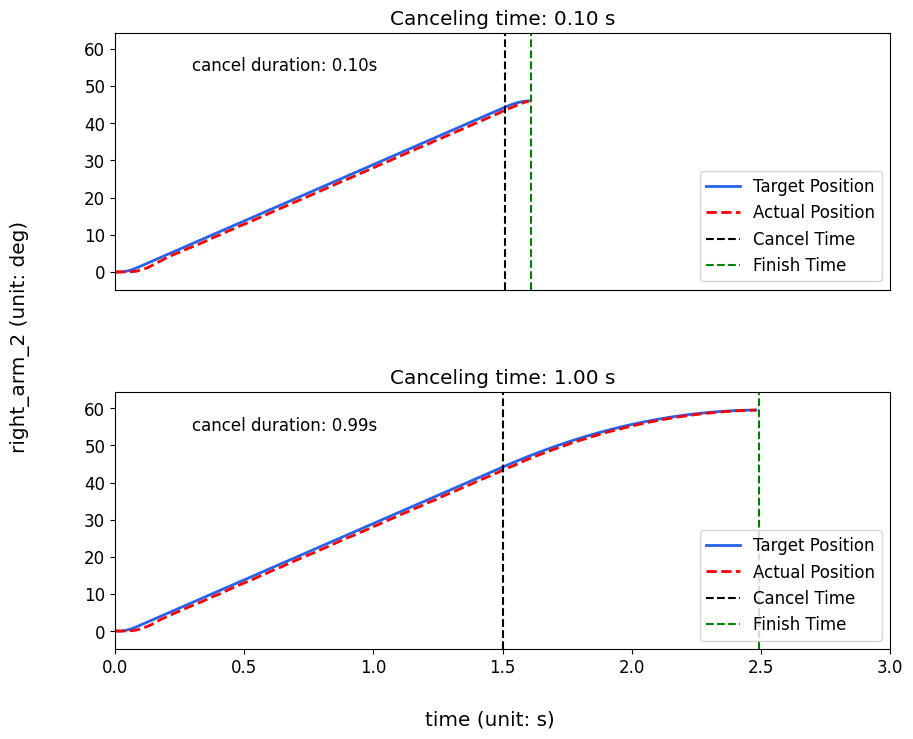

In [26]:
print("===== Canceling Time Demo =====")
joint_index = int(model.right_arm_idx[RECORD_JOINT_INDEX])      # 10
joint_label = model.robot_joint_names[joint_index]              # 'right_arm_2'

validate_parameter(robot, canceling_time_param)                 # "joint_position_command.canceling_time"
original_value = robot.get_parameter(canceling_time_param)

print(f"Using canceling_time parameter: {canceling_time_param}")
print(f"Original value: {original_value}")
print(f"Recording joint: {joint_label} (index {joint_index})")

# Keep the same start pose for both trials so the graph comparison is meaningful.
# Set Zero Posture
Desired_Pos = fn.ZERO_POS                             # ZERO_POS, READY_POS, PACK_POS, READY_DEMO_POS
fn.move_position_22dof(robot, Desired_Pos, minimum_time=5.0, control_hold_time=0.5)
time.sleep(1)

home_state = robot.get_state()
home_right_arm = home_state.position[model.right_arm_idx].copy()        # 현재 right_arm 7-DoF position
movej(robot, right_arm=home_right_arm, minimum_time=2.0)
time.sleep(0.3)

results = []

try:
    for idx, canceling_time in enumerate(canceling_times):
        logging.info("Running trial with canceling_time=%.2f s", canceling_time)
        result = run_trial(
            robot=robot,
            home_right_arm=home_right_arm,
            joint_index=joint_index,                        # 10
            canceling_time=canceling_time,                  # 0.1, 1.0
            canceling_time_param=canceling_time_param,
            target_delta_deg=TARGET_DELTA_DEG,
            cancel_after_sec=cancel_after_sec,              # 1.5
            minimum_time=minimum_time,
        )
        results.append(result)

        if not robot.set_parameter(canceling_time_param, original_value):
            raise RuntimeError(f"Failed to restore {canceling_time_param}")

        if idx < len(canceling_times) - 1:
            movej(robot, right_arm=home_right_arm, minimum_time=2.0)
            time.sleep(0.3)
            
    plot_results(results, cancel_after_sec, joint_label)
finally:
    try:
        robot.set_parameter(canceling_time_param, original_value)
    except Exception:
        pass

    try:
        robot.cancel_control()
    except Exception:
        pass

    try:
        movej(robot, right_arm=home_right_arm, minimum_time=2.0)
    except Exception:
        pass